## 11. Markov連鎖Monte Carlo法
### 11.2 Markov連鎖
#### 例題11.1

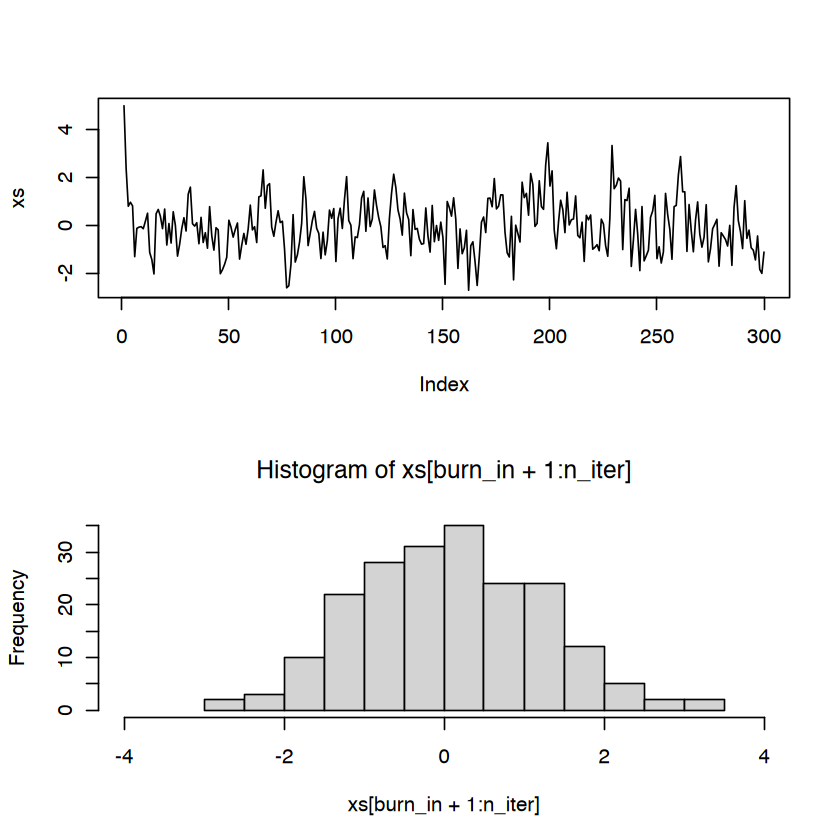

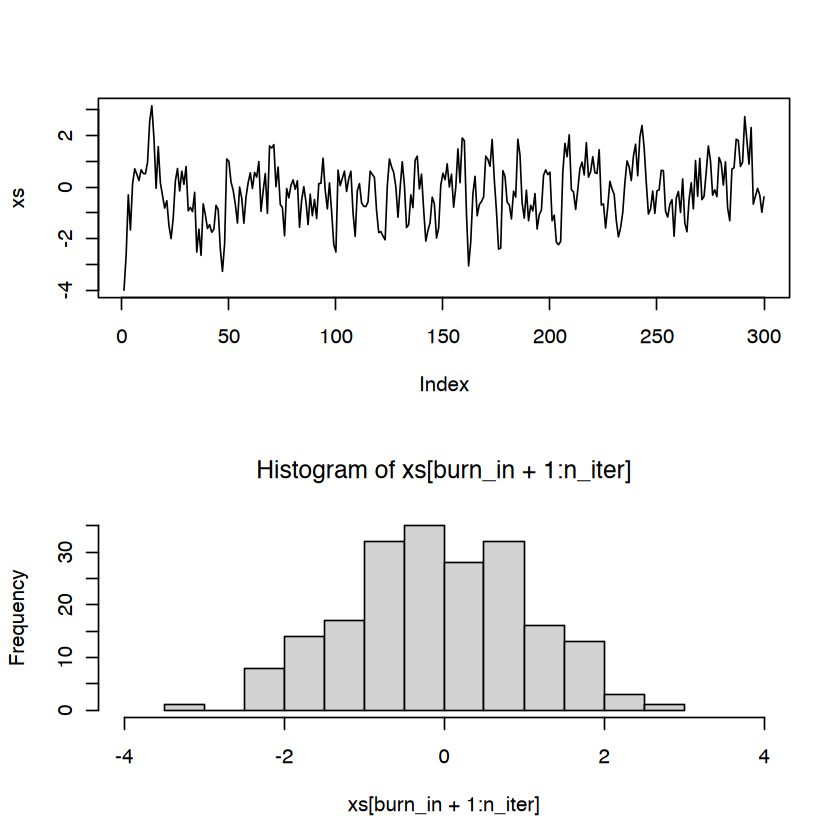

In [1]:
ex11_1 <- function(n_iter, burn_in, sigma, x_init) {
  xs <- numeric(n_iter)
  xs[1] <- x_init

  for (i in 1:(n_iter-1)) {
    xs[i + 1] <- rnorm(n = 1, mean = 0.5*xs[i], sd = sigma)
  }

  par(mfrow=c(2, 1))
  par(bg = "white")
  plot(xs, type = "l")
  hist(xs[burn_in+1:n_iter], xlim = c(-4, 4))
}

ex11_1(300, 100, 1, 5)
ex11_1(300, 100, 1, -4)

### 2種類のsampler
#### 例題11.5

In [2]:
ex11_5 <- function(n_iter, burn_in, a, b, sigma, x_init) {
  target <- function(x) {
    return(dnorm(x, mean = 0, sd = 1))
  }

  sampler <- function(y, x) {
    return(dnorm(y, mean = a*x+b, sd = sigma))
  }

  sampler_sample <- function(x) {
    rnorm(n = 1, mean = a*x+b, sd = sigma)
  }

  samples <- numeric(n_iter)
  samples[1] <- x_init

  for (i in 1:(n_iter-1)) {
    y <- sampler_sample(samples[i])
    alpha <- min(1, (target(y)*sampler(samples[i], y)) / (target(samples[i])*sampler(y, samples[i])))
    if (runif(1) < alpha) {
      samples[i+1] <- y
    } else {
      samples[i+1] <- samples[i]
    }
  }

  par(mfrow=c(2, 1))
  par(bg = "white")
  plot(samples, type = "l", ylim = c(-4, 4))
  hist(samples[burn_in+1:n_iter], xlim = c(-4, 4))
}

Metropolis sampler

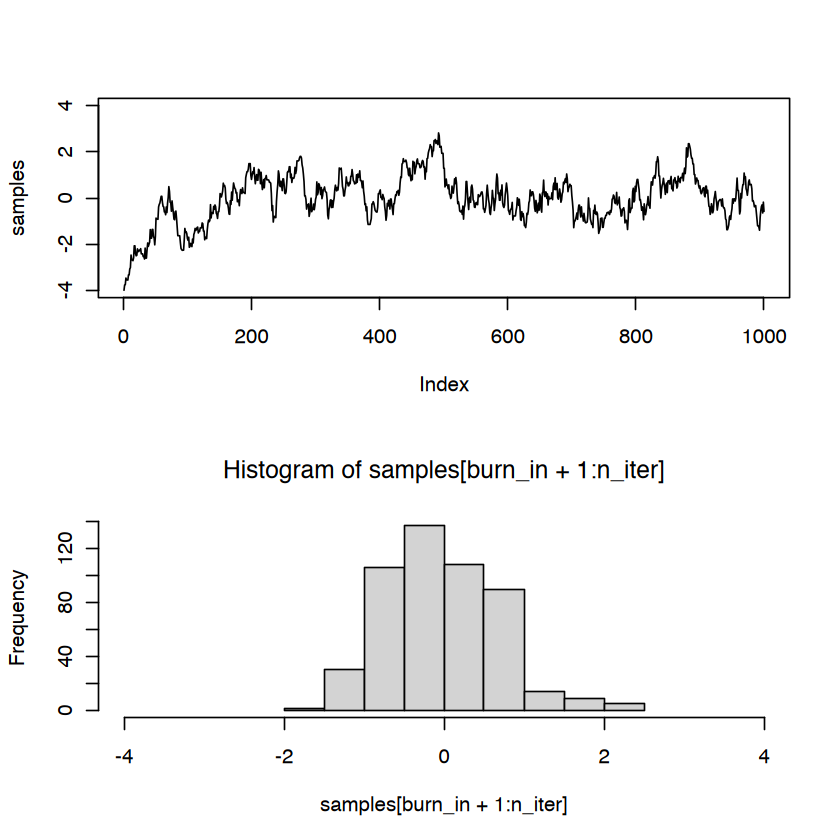

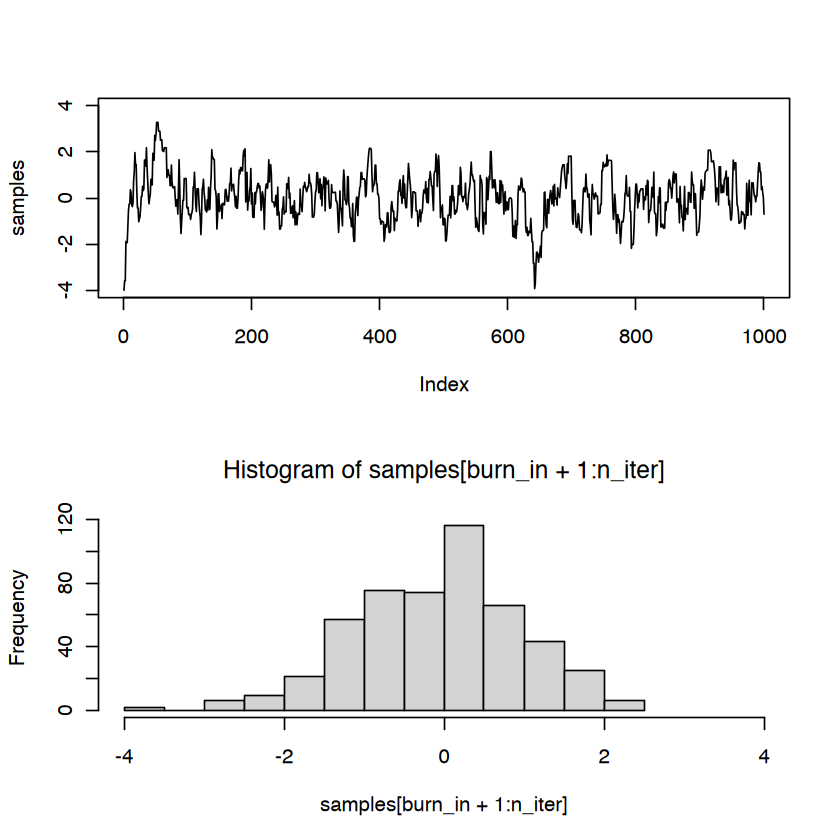

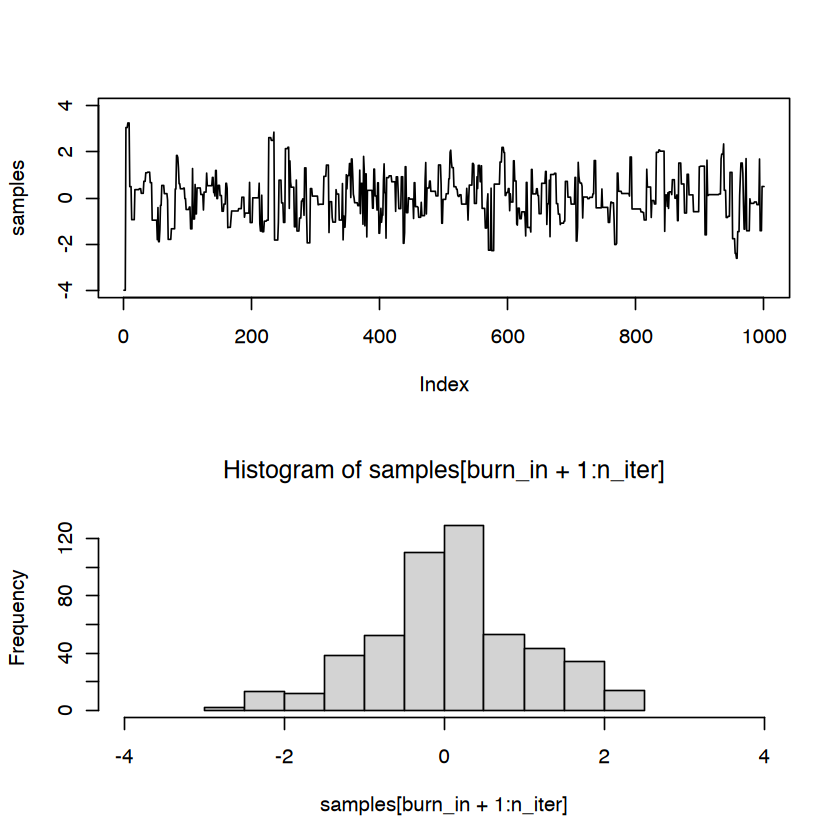

In [3]:
ex11_5(1000, 500, 1, 0, sqrt(0.1), -4)
ex11_5(1000, 500, 1, 0, sqrt(0.5), -4)
ex11_5(1000, 500, 1, 0, sqrt(10), -4)

independence sampler

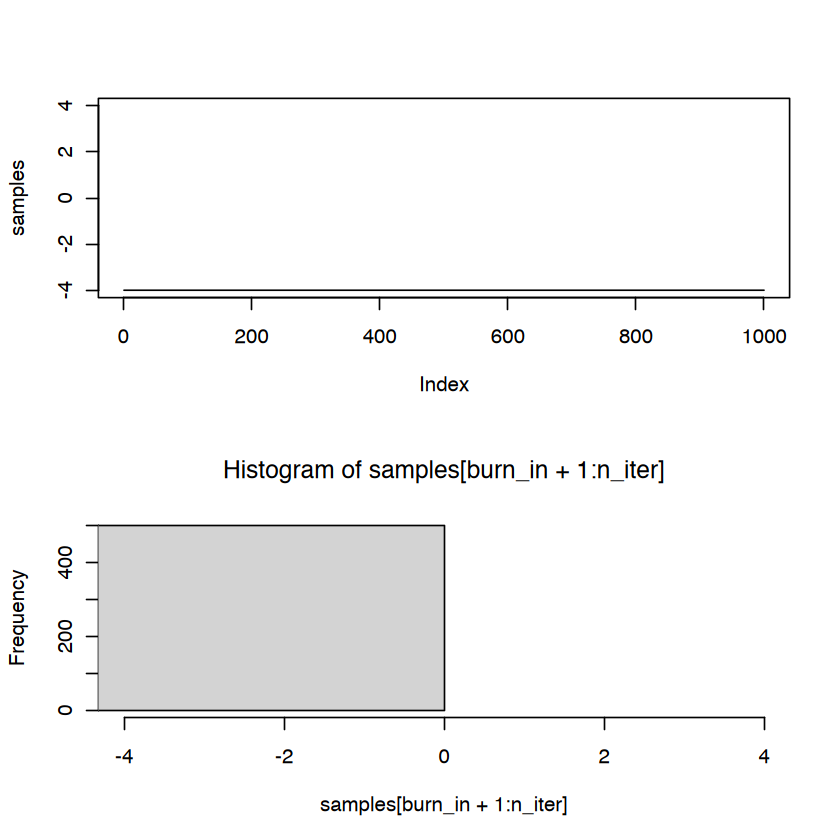

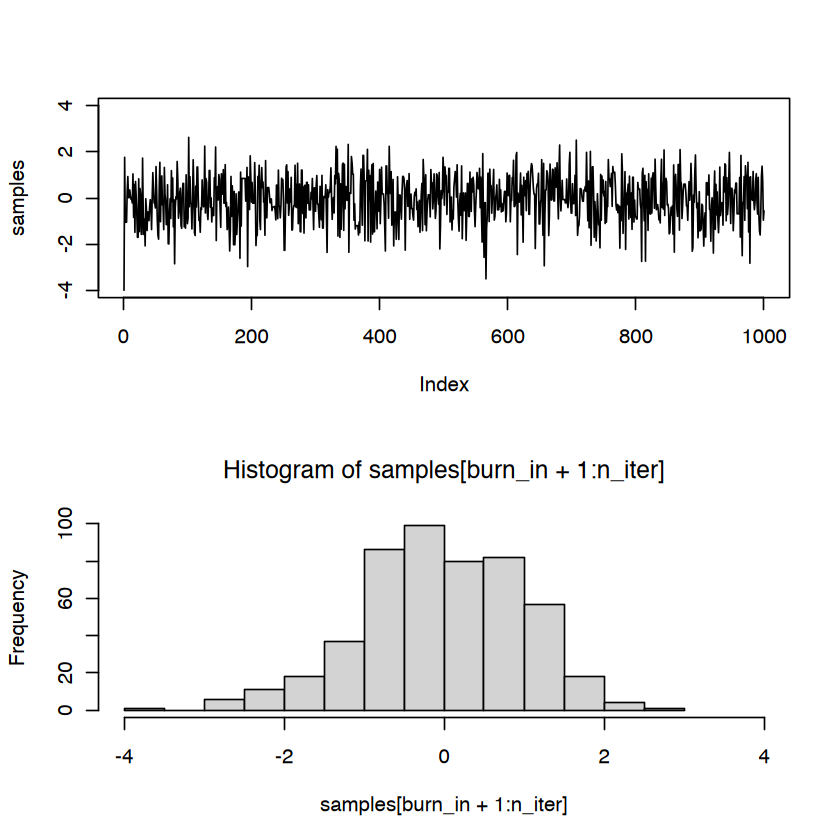

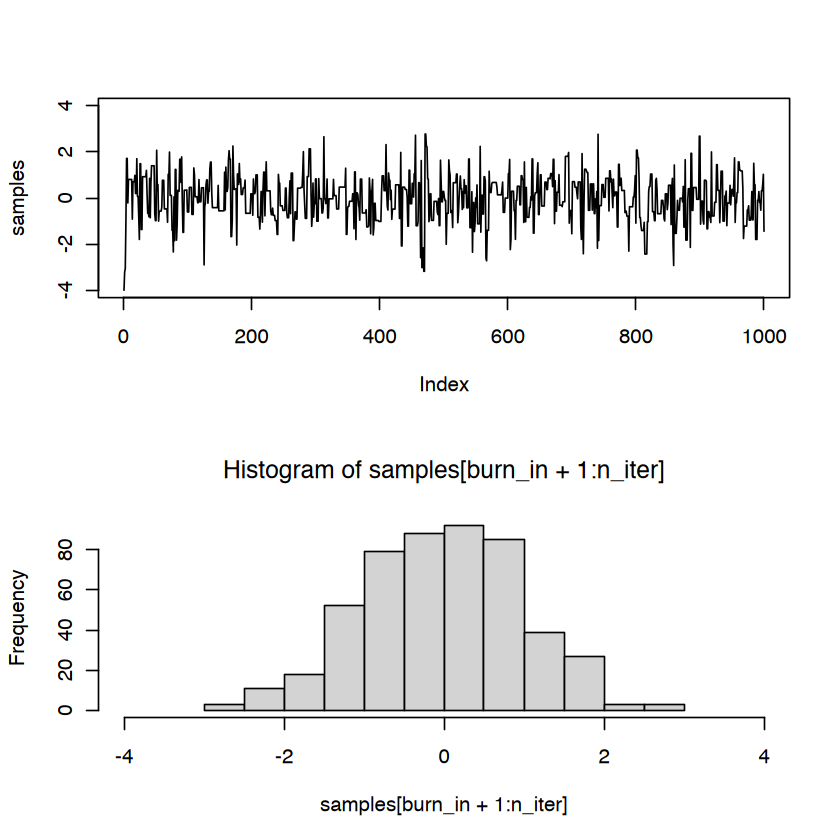

In [4]:
ex11_5(1000, 500, 0, 0, sqrt(0.5), -4)
ex11_5(1000, 500, 0, 0, sqrt(1.5), -4)
ex11_5(1000, 500, 0, 0, sqrt(5), -4)

### 11.6 single-component MH法
#### 例題11.6

alpha (std) 0.7466163 0.1257296 2.389017 
alpha -65.47015 
beta (std) 2.490743 0.2063327 0.4646351 
beta 36.92299

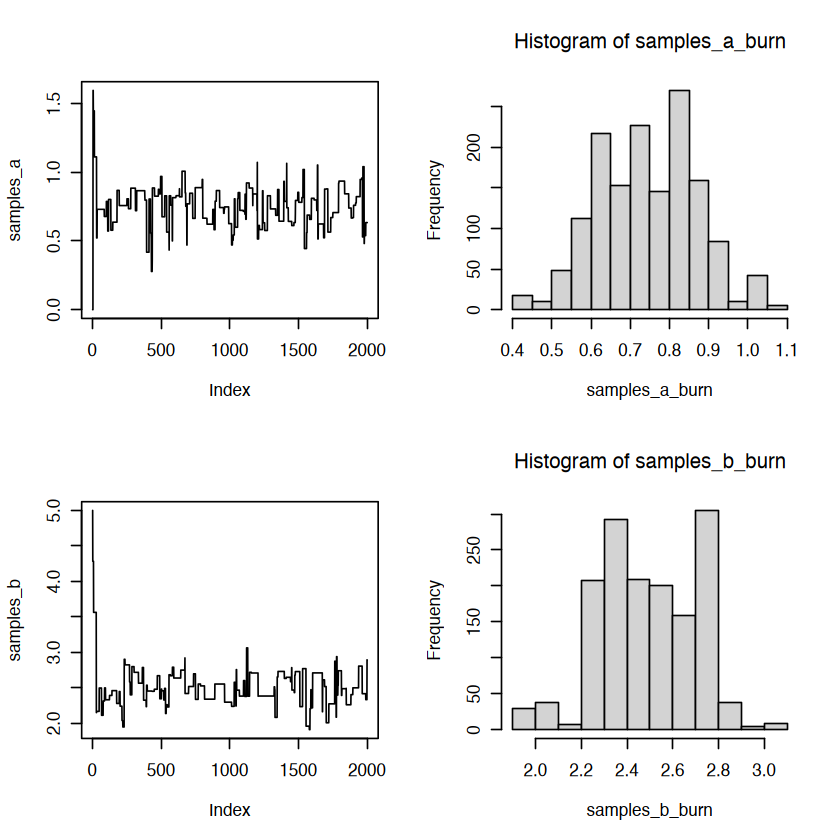

alpha (std) 0.746618 0.1380392 4.186798 
alpha -65.35784 
beta (std) 2.486519 0.2179216 5.284222 
beta 36.86036

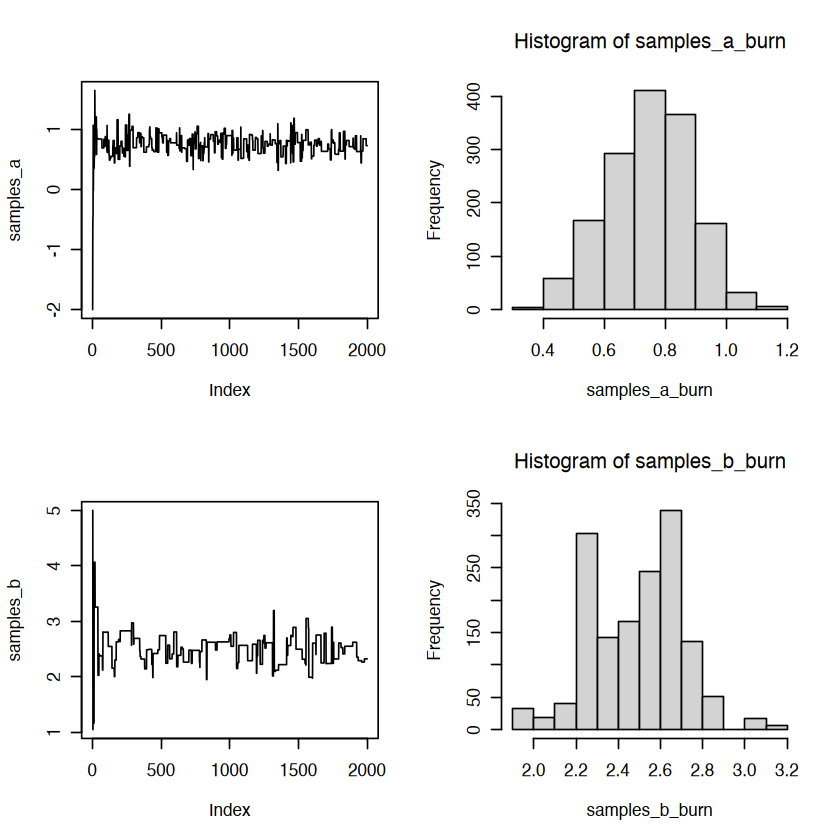

alpha (std) 0.707717 0.1183844 -3.795851 
alpha -63.87283 
beta (std) 2.429197 0.196568 3.72792 
beta 36.01062

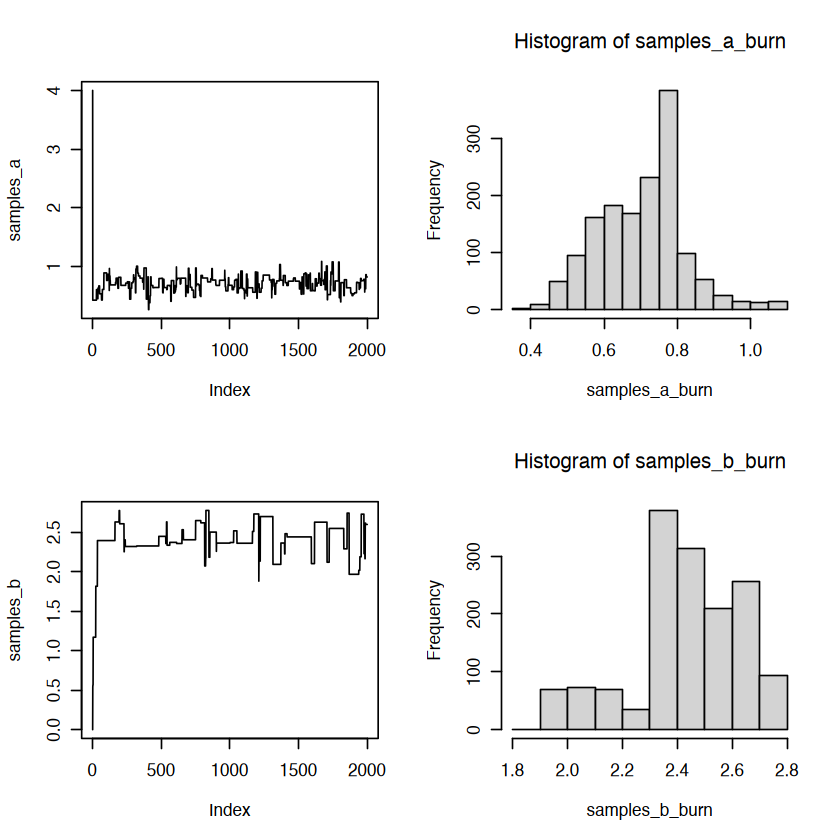

In [5]:
ex11_6 <- function(n_iter, burn_in, sigmaa, sigmab, a_init, b_init) {
  x <- c(1.691, 1.724, 1.755, 1.784, 1.811, 1.837, 1.861, 1.884)
  z <- (x - mean(x)) / sqrt(var(x))
  n <- c(59, 60, 62, 56, 63, 59, 62, 60)
  m <- c(4, 10, 19, 31, 52, 53, 60, 60)

  logf <- function(a, b) {
    theta <- 1 / (1 + exp(-(a+b*z)))
    return(sum(m*log(theta) + (n-m)*log(1-theta)))
    # choose(n, m)は採択確立f/fの計算で消えるので不要
  }

  sampler_a_sample <- function() {
    rnorm(n = 1, mean = 0, sd = sigmaa)
  }

  sampler_b_sample <- function() {
    rnorm(n = 1, mean = 0, sd = sigmab)
  }

  samples_a <- numeric(n_iter)
  samples_b <- numeric(n_iter)
  samples_a[1] <- a_init
  samples_b[1] <- b_init

  for (i in 1:(n_iter-1)) {
    y_a <- sampler_a_sample()
    logalpha <- min(0, logf(y_a, samples_b[i]) - logf(samples_a[i], samples_b[i]))
    if (log(runif(1)) < logalpha) {
      samples_a[i+1] <- y_a
    } else {
      samples_a[i+1] <- samples_a[i]
    }

    y_b <- sampler_b_sample()
    logbeta <- min(0, logf(samples_a[i+1], y_b) - logf(samples_a[i+1], samples_b[i]))
    if (log(runif(1)) < logbeta) {
      samples_b[i+1] <- y_b
    } else {
      samples_b[i+1] <- samples_b[i]
    }
  }

  samples_a_burn <- as.vector(na.omit(samples_a[burn_in+1:n_iter]))
  samples_b_burn <- as.vector(na.omit(samples_b[burn_in+1:n_iter]))

  samples_a_burn_first <- samples_a_burn[1:floor(length(samples_a_burn)/2)]
  samples_a_burn_latter <- samples_a_burn[(floor(length(samples_a_burn)/2)+1):length(samples_a_burn)]

  samples_b_burn_first <- samples_b_burn[1:floor(length(samples_b_burn)/2)]
  samples_b_burn_latter <- samples_b_burn[(floor(length(samples_b_burn)/2)+1):length(samples_b_burn)]

  Za <- (mean(samples_a_burn_first) - mean(samples_a_burn_latter)) / sqrt(var(samples_a_burn_first) + var(samples_a_burn_latter)) * sqrt((n_iter - burn_in)/2)
  Zb <- (mean(samples_b_burn_first) - mean(samples_b_burn_latter)) / sqrt(var(samples_b_burn_first) + var(samples_b_burn_latter)) * sqrt((n_iter - burn_in)/2)

  par(mfrow=c(2, 2))
  par(bg = "white")
  plot(samples_a, type = "l")
  hist(samples_a_burn)

  plot(samples_b, type = "l")
  hist(samples_b_burn)

  alpha_est = mean(samples_a_burn)
  beta_est = mean(samples_b_burn)

  cat("alpha (std)", alpha_est, sqrt(var(samples_a_burn)), Za, "\n")
  cat("alpha", alpha_est - mean(x) * beta_est / sqrt(var(x)), "\n")
  cat("beta (std)", beta_est, sqrt(var(samples_b_burn)), Zb, "\n")
  cat("beta", beta_est / sqrt(var(x)))
}

ex11_6(2000, 500, sqrt(5), sqrt(5), 0, 5)
ex11_6(2000, 500, 1, sqrt(3), -2, 5)
ex11_6(2000, 500, sqrt(0.5), sqrt(1.5), 4, 0)

### 11.7 Gibbs sampling
#### 例題11.7

U = 0.9373 , X = 0.7062 , pi(X)/PI(X) = 0.0158 


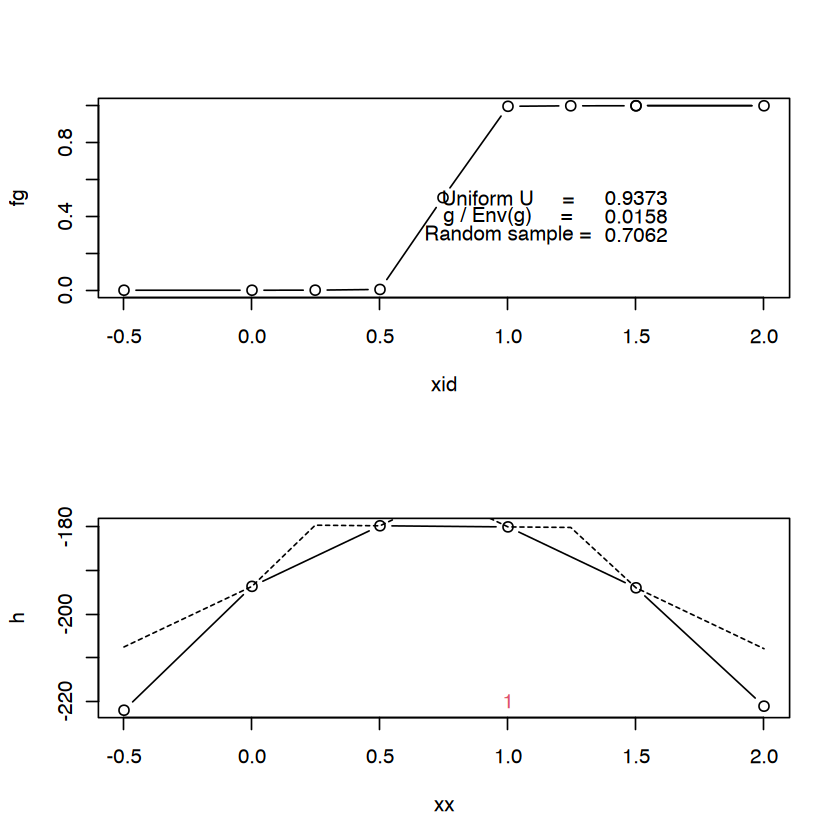

U = 0.187 , X = 0.8828 , pi(X)/PI(X) = 0.1505 


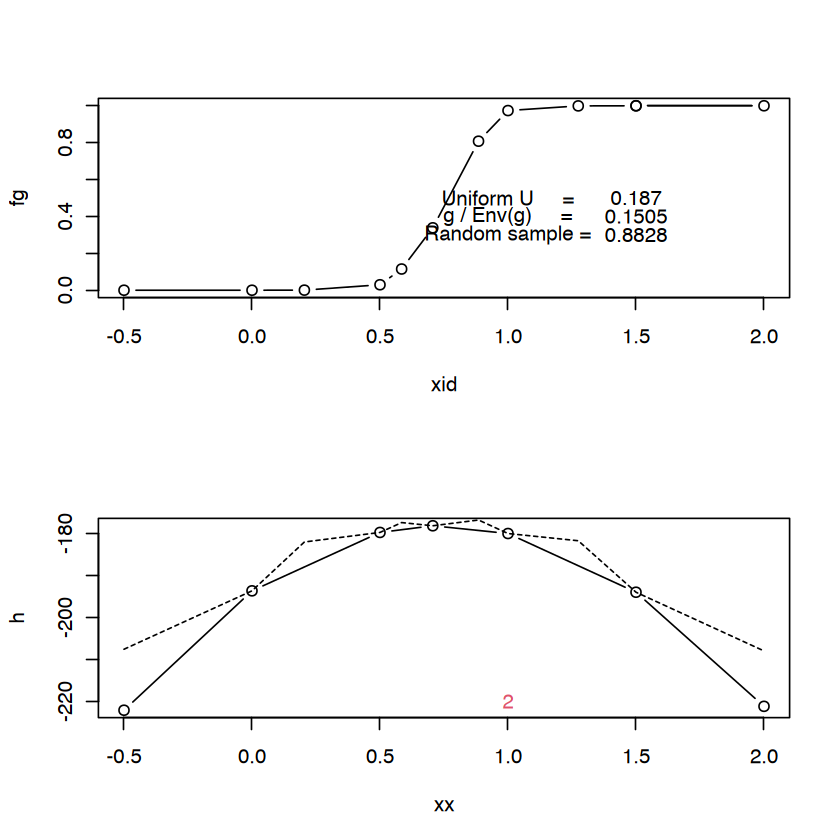

U = 0.8994 , X = 0.5913 , pi(X)/PI(X) = 0.3919 


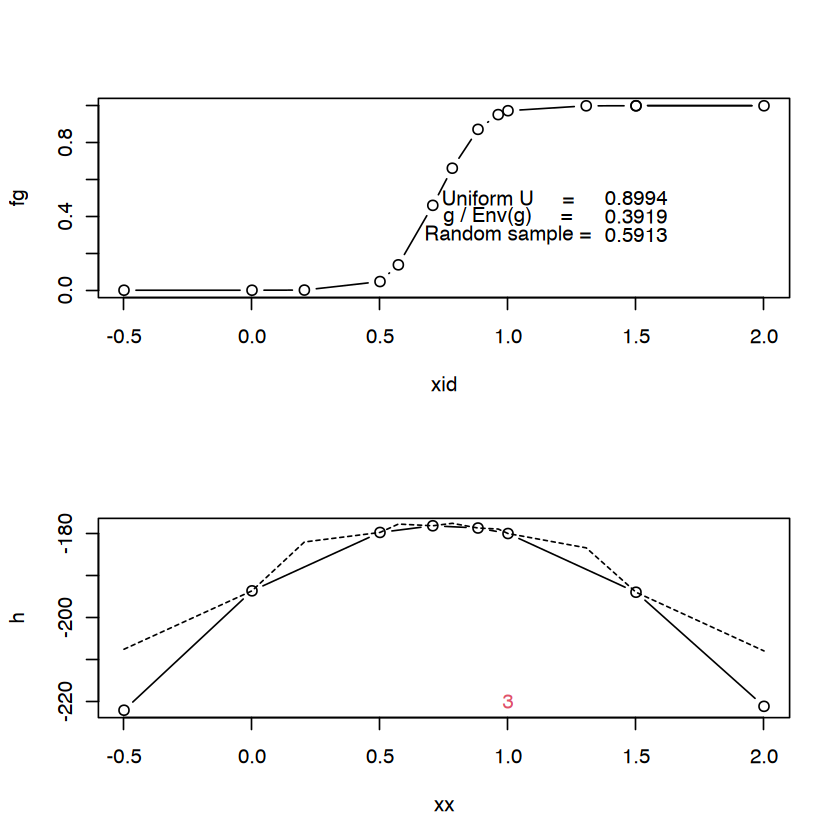

U = 0.4781 , X = 0.6393 , pi(X)/PI(X) = 0.8281 


[1] 0.6393076

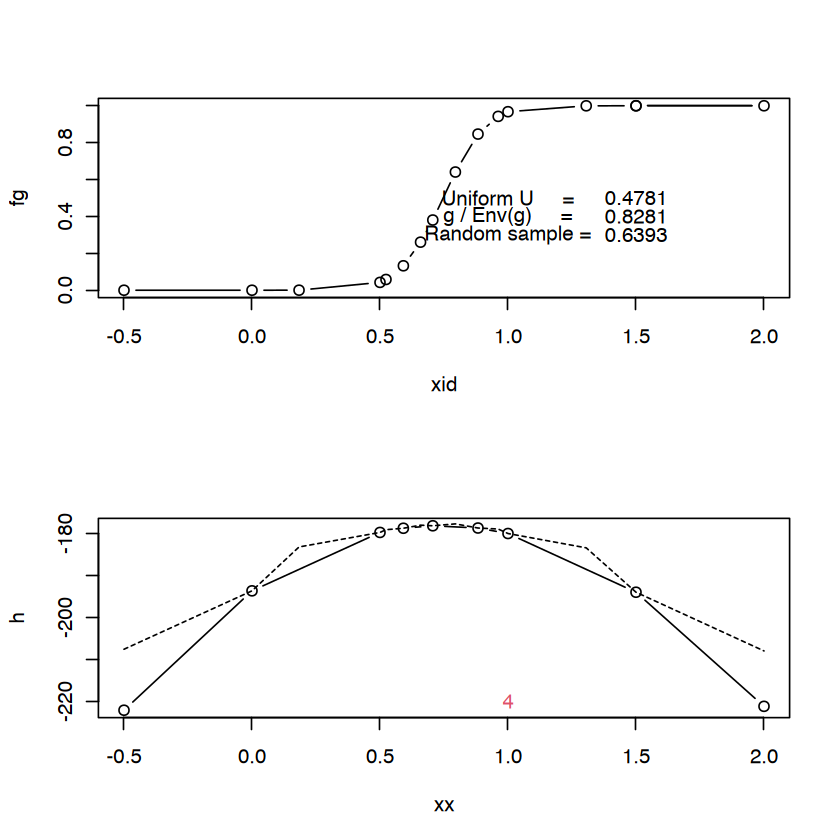

In [6]:
# appendix B.7 ( Figure 10.6, 10.7)
#
# There are 3 functions: lga(), lgb(), arsal()
#
par(mfrow=c(2, 1))
par(bg = "white")

# FUNCTION: log-likelihood for alpha
lga <- function(alp, bet, sda, z, n, m){
  th <- alp + bet*z
  sum( m*th - n*log(1 + exp(th)) ) - (alp^2) / (2*sda^2) # (11.37)
}

# FUNCTION: log-likelihood for beta
lgb <- function(alp, bet, sdb, z, n, m){
  th <- alp + bet*z
  sum( m*th - n*log(1 + exp(th)) ) - (bet^2) / (2*sdb^2) # (11.38)
}

# FUNCTION : adaptive rejection sampling for alpha
# initial abscissae : { mu, xab(i), i=1,....,mu }
arsal <- function(mu, xab, pb, sd, z, n, m) {
  jk <- 0
  u2 <- 1
  rat <- 0
  while(u2 > rat){
    jk <- jk + 1
    xx <- sort(xab) # {(x, pi(x)) for x in S}のx座標；{x for x in S}

    h <- 1:mu # {(x, pi(x)) for x in S}のy座標；{pi(x) for x in S}
    for (i in 1:mu){ h[i] <- lga(xx[i], pb, sd, z, n, m) }

    st <- 1:(mu-1)
    for (i in 1:(mu-1)){ st[i] <- (h[i] - h[i+1]) / (xx[i] - xx[i+1]) }

    ss <- 1:(2*mu-2)
    ss[1] <- st[1]; ss[2] <- st[2]
    for (i in 2:(mu-2)){ ss[2*i-1] <- st[i-1]; ss[2*i] <- st[i+1] }
    ss[2*mu-3] <- st[mu-2]
    ss[2*mu-2] <- st[mu-1]

    xc <- 1:(2*mu-3) # PI_S(X)が折れ曲がる点のx座標（Sの区間のうち，最初と最後以外に凸点があるため，mu+(mu-1-2)=2mu-3）
    xc[1] <- xx[1]
    for (i in 2:(mu-2)){
      xc[2*i-2] <- xx[i]
      xc[2*i-1] <- (h[i+1] - h[i] + st[i-1]*xx[i] - st[i+1]*xx[i+1]) / (st[i-1] - st[i+1]) }
    xc[2*mu-4] <- xx[mu-1]
    xc[2*mu-3] <- xx[mu]

    cu <- 1:(2*mu-2)
    cu[1] <- h[1] - st[1]*xx[1]
    cu[2] <- h[2] - st[2]*xx[2]
    for (i in 2:(mu-2)) {
      cu[2*i-1] <- h[i] - st[i-1]*xx[i]
      cu[2*i]   <- h[i+1] - st[i+1]*xx[i+1]
    }
    cu[2*mu-3] <- h[mu-1] - st[mu-2]*xx[mu-1]
    cu[2*mu-2] <- h[mu] - st[mu-1]*xx[mu]

    yy <- 1:(2*mu-3) # PI_S(X)が折れ曲がる点のy座標
    yy[1] <- st[2]*xx[1] + cu[2]
    for (i in 2:(mu-2)) {
      yy[2*i-2] <- h[i]
      yy[2*i-1] <- ss[2*i-1]*xc[2*i-1] + cu[2*i-1]
    }
    yy[2*mu-4] <- h[mu-1]
    yy[2*mu-3] <- ss[2*mu-3]*xx[mu] + cu[2*mu-3]


    ff <- 1:(2*mu-2)
    s <- 0
    ff[1] <- exp(ss[1]*xc[1] + cu[1]) / ss[1]
    for (i in 2:(2*mu-3)) {
      ff[i] <- exp(cu[i])*(exp(ss[i]*xc[i]) - exp(ss[i]*xc[i - 1])) / ss[i]
      s <- s + ff[i]
    }
    ff[2*mu - 2] <- -exp(ss[2*mu-2]*xc[2*mu-3] + cu[2*mu - 2]) / ss[2*mu-2]

    s <- s + ff[1] + ff[2*mu-2]

    for (i in 1:(2*mu-2)) { ff[i] <- ff[i] / s }

    fg <- rep(0, 2*mu - 2)
    for (i in 1:(2*mu - 2)) {
      for (j in 1:i) {
        fg[i] <- fg[i] + ff[j]
      }
    }

    u <- runif(1, 0, 1)
    xprob <- 0
    i <- 0

    while(u > xprob) { i<-i+1; xprob<-fg[i] }

    k <- i
    ud <- ifelse(k>1, u-fg[k-1], u)
    aaa <- ifelse(k>1, exp(ss[k]*xc[k-1]), 0)
    xget <- log(aaa + s*ud*ss[k]/exp(cu[k])) / ss[k]

    u2 <- runif(1, 0, 1)
    t1 <- lga(xget, pb, sd, z, n, m)
    t2 <- ss[k]*xget+cu[k]
    rat <- exp(t1-t2)
    #
    # plot only for Figure 10.7
    #
    xid<-c(xc, 1.5)
    plot(xid, fg, pch=1, type="b")

    text(1.0, 0.5, " Uniform U     = ")
    text(1.5, 0.5, round(u2, 4))
    text(1.0, 0.4, " g / Env(g)     = ")
    text(1.5, 0.4, round(rat, 4))
    text(1.0, 0.3, " Random sample = ")
    text(1.5, 0.3, round(xget, 4))
    plot(xx, h, pch=1, type="b") # pi(x)
    # plot(xx, h, pch=1, type="b", ylim=c(-230, -150))
    lines(xc, yy, pch=2, lty=2) # PI_S(X)
    text(1.0, -220, jk, col=2)
    #
    xab <- c(xab, xget)
    mu <- mu + 1

    cat("U =", round(u2, 4), ", X =", round(xget, 4), ", pi(X)/PI(X) =", round(rat, 4), "\n")
  }
  return(xget) # U > Xを満たしたX
}

# main program
# data Input (table 6.1)
x <- c(1.691, 1.724, 1.755, 1.784, 1.811, 1.837, 1.861, 1.884)
z <- (x - mean(x)) / sqrt(var(x))
n <- c(59, 60, 62, 56, 63, 59, 62, 60)
m <- c(4, 10, 19, 31, 52, 53, 60, 60)

# 集合Sの初期値
mu <- 6; xab <- 1:mu
xab[1] <- -0.5; xab[2] <- 0.0; xab[3] <- 0.5
xab[4] <- 1.0; xab[5] <- 1.5; xab[6] <- 2.0

# initial values for alp, bet, sda(sd of alpha)
sda <- 1.0; alp <- 2; bet <- 2.5
arsal(mu, xab, bet, sda, z, n, m)

#### 例題11.8

alpha (std) 0.705236 0.1392575 -1.985411 
alpha -63.52319 
beta (std) 2.497344 0.2165315 -1.189986 
beta 35.83925

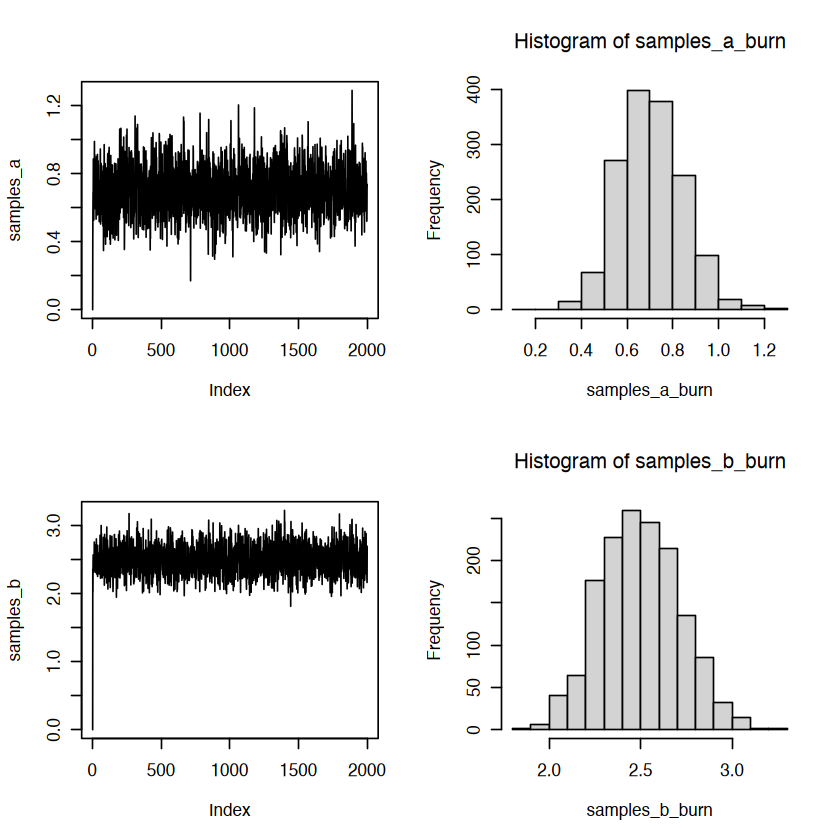

alpha (std) 0.672174 0.1340371 -0.5716367 
alpha -61.22918 
beta (std) 2.406862 0.2025408 -0.05291768 
beta 34.54076

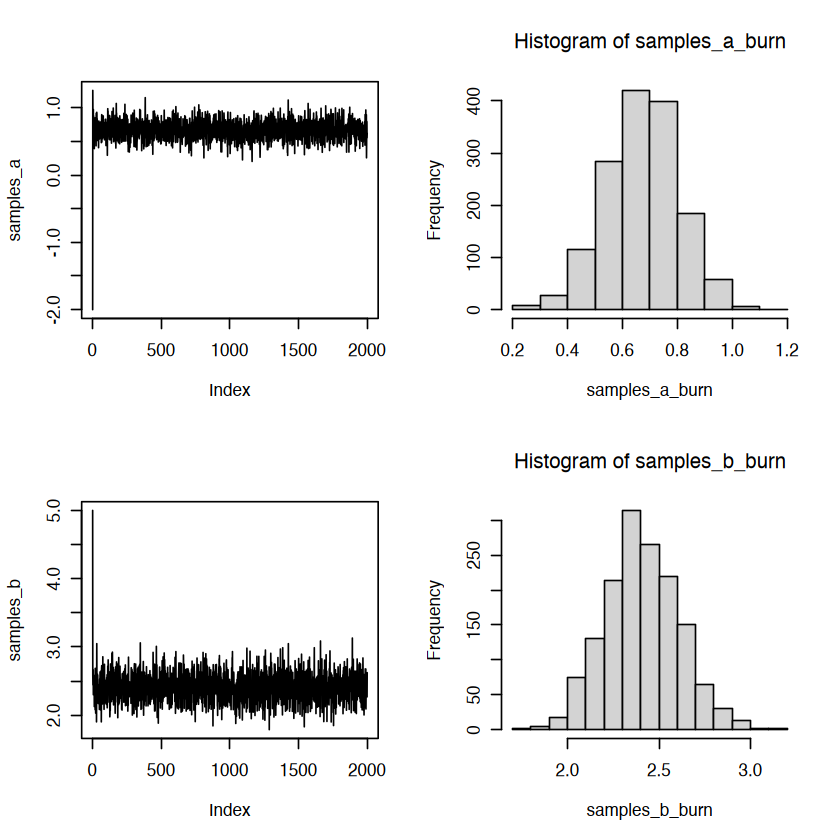

In [7]:
# FUNCTION: log-likelihood for alpha
lga <- function(alp, bet, sda, z, n, m){
  th <- alp + bet*z
  sum( m*th - n*log(1 + exp(th)) ) - (alp^2) / (2*sda^2) # (11.37)
}

# FUNCTION: log-likelihood for beta
lgb <- function(alp, bet, sdb, z, n, m){
  th <- alp + bet*z
  sum( m*th - n*log(1 + exp(th)) ) - (bet^2) / (2*sdb^2) # (11.38)
}

# FUNCTION : adaptive rejection sampling for alpha
# initial abscissae : { mu, xab(i), i=1,....,mu }
arsal <- function(mu, xab, pb, sd, z, n, m) {
  jk <- 0
  u2 <- 1
  rat <- 0
  while(u2 > rat){
    jk <- jk + 1
    xx <- sort(xab) # {(x, pi(x)) for x in S}のx座標；{x for x in S}

    h <- 1:mu # {(x, pi(x)) for x in S}のy座標；{pi(x) for x in S}
    for (i in 1:mu){ h[i] <- lga(xx[i], pb, sd, z, n, m) }

    st <- 1:(mu-1)
    for (i in 1:(mu-1)){ st[i] <- (h[i] - h[i+1]) / (xx[i] - xx[i+1]) }

    ss <- 1:(2*mu-2)
    ss[1] <- st[1]; ss[2] <- st[2]
    for (i in 2:(mu-2)){ ss[2*i-1] <- st[i-1]; ss[2*i] <- st[i+1] }
    ss[2*mu-3] <- st[mu-2]
    ss[2*mu-2] <- st[mu-1]

    xc <- 1:(2*mu-3) # PI_S(X)が折れ曲がる点のx座標（Sの区間のうち，最初と最後以外に凸点があるため，mu+(mu-1-2)=2mu-3）
    xc[1] <- xx[1]
    for (i in 2:(mu-2)){
      xc[2*i-2] <- xx[i]
      xc[2*i-1] <- (h[i+1] - h[i] + st[i-1]*xx[i] - st[i+1]*xx[i+1]) / (st[i-1] - st[i+1]) }
    xc[2*mu-4] <- xx[mu-1]
    xc[2*mu-3] <- xx[mu]

    cu <- 1:(2*mu-2)
    cu[1] <- h[1] - st[1]*xx[1]
    cu[2] <- h[2] - st[2]*xx[2]
    for (i in 2:(mu-2)) {
      cu[2*i-1] <- h[i] - st[i-1]*xx[i]
      cu[2*i]   <- h[i+1] - st[i+1]*xx[i+1]
    }
    cu[2*mu-3] <- h[mu-1] - st[mu-2]*xx[mu-1]
    cu[2*mu-2] <- h[mu] - st[mu-1]*xx[mu]

    yy <- 1:(2*mu-3) # PI_S(X)が折れ曲がる点のy座標
    yy[1] <- st[2]*xx[1] + cu[2]
    for (i in 2:(mu-2)) {
      yy[2*i-2] <- h[i]
      yy[2*i-1] <- ss[2*i-1]*xc[2*i-1] + cu[2*i-1]
    }
    yy[2*mu-4] <- h[mu-1]
    yy[2*mu-3] <- ss[2*mu-3]*xx[mu] + cu[2*mu-3]

    ff <- 1:(2*mu-2)
    s <- 0
    ff[1] <- exp(ss[1]*xc[1] + cu[1]) / ss[1]
    for (i in 2:(2*mu-3)) {
      ff[i] <- exp(cu[i])*(exp(ss[i]*xc[i]) - exp(ss[i]*xc[i - 1])) / ss[i]
      s <- s + ff[i]
    }
    ff[2*mu - 2] <- -exp(ss[2*mu-2]*xc[2*mu-3] + cu[2*mu - 2]) / ss[2*mu-2]

    s <- s + ff[1] + ff[2*mu-2]

    for (i in 1:(2*mu-2)) { ff[i] <- ff[i] / s }

    fg <- rep(0, 2*mu - 2)
    for (i in 1:(2*mu - 2)) {
      for (j in 1:i) {
        fg[i] <- fg[i] + ff[j]
      }
    }

    u <- runif(1, 0, 1)
    xprob <- 0
    i <- 0

    while(u > xprob) { i<-i+1; xprob<-fg[i] }

    k <- i
    ud <- ifelse(k>1, u-fg[k-1], u)
    aaa <- ifelse(k>1, exp(ss[k]*xc[k-1]), 0)
    xget <- log(aaa + s*ud*ss[k]/exp(cu[k])) / ss[k]

    u2 <- runif(1, 0, 1)
    t1 <- lga(xget, pb, sd, z, n, m)
    t2 <- ss[k]*xget+cu[k]
    rat <- exp(t1-t2)

    xab <- c(xab, xget)
    mu <- mu + 1
  }
  return(xget)
}

# FUNCTION : adaptive rejection sampling for beta
# initial abscissae : { mu, xab(i), i=1,....,mu }
arsbe <- function(mu, yab, pa, sd, z, n, m) {
  jk <- 0
  u2 <- 1
  rat <- 0
  while(u2 > rat){
    jk <- jk + 1
    xx <- sort(yab) # {(x, pi(x)) for x in S}のx座標；{x for x in S}

    h <- 1:mu # {(x, pi(x)) for x in S}のy座標；{pi(x) for x in S}
    for (i in 1:mu){ h[i] <- lgb(pa, xx[i], sd, z, n, m) }

    st <- 1:(mu-1)
    for (i in 1:(mu-1)){ st[i] <- (h[i] - h[i+1]) / (xx[i] - xx[i+1]) }

    ss <- 1:(2*mu-2)
    ss[1] <- st[1]; ss[2] <- st[2]
    for (i in 2:(mu-2)){ ss[2*i-1] <- st[i-1]; ss[2*i] <- st[i+1] }
    ss[2*mu-3] <- st[mu-2]
    ss[2*mu-2] <- st[mu-1]

    xc <- 1:(2*mu-3) # PI_S(X)が折れ曲がる点のx座標（Sの区間のうち，最初と最後以外に凸点があるため，mu+(mu-1-2)=2mu-3）
    xc[1] <- xx[1]
    for (i in 2:(mu-2)){
      xc[2*i-2] <- xx[i]
      xc[2*i-1] <- (h[i+1] - h[i] + st[i-1]*xx[i] - st[i+1]*xx[i+1]) / (st[i-1] - st[i+1]) }
    xc[2*mu-4] <- xx[mu-1]
    xc[2*mu-3] <- xx[mu]

    cu <- 1:(2*mu-2)
    cu[1] <- h[1] - st[1]*xx[1]
    cu[2] <- h[2] - st[2]*xx[2]
    for (i in 2:(mu-2)) {
      cu[2*i-1] <- h[i] - st[i-1]*xx[i]
      cu[2*i]   <- h[i+1] - st[i+1]*xx[i+1]
    }
    cu[2*mu-3] <- h[mu-1] - st[mu-2]*xx[mu-1]
    cu[2*mu-2] <- h[mu] - st[mu-1]*xx[mu]

    yy <- 1:(2*mu-3) # PI_S(X)が折れ曲がる点のy座標
    yy[1] <- st[2]*xx[1] + cu[2]
    for (i in 2:(mu-2)) {
      yy[2*i-2] <- h[i]
      yy[2*i-1] <- ss[2*i-1]*xc[2*i-1] + cu[2*i-1]
    }
    yy[2*mu-4] <- h[mu-1]
    yy[2*mu-3] <- ss[2*mu-3]*xx[mu] + cu[2*mu-3]

    ff <- 1:(2*mu-2)
    s <- 0
    ff[1] <- exp(ss[1]*xc[1] + cu[1]) / ss[1]
    for (i in 2:(2*mu-3)) {
      ff[i] <- exp(cu[i])*(exp(ss[i]*xc[i]) - exp(ss[i]*xc[i - 1])) / ss[i]
      s <- s + ff[i]
    }
    ff[2*mu - 2] <- -exp(ss[2*mu-2]*xc[2*mu-3] + cu[2*mu - 2]) / ss[2*mu-2]

    s <- s + ff[1] + ff[2*mu-2]

    for (i in 1:(2*mu-2)) { ff[i] <- ff[i] / s }

    fg <- rep(0, 2*mu - 2)
    for (i in 1:(2*mu - 2)) {
      for (j in 1:i) {
        fg[i] <- fg[i] + ff[j]
      }
    }

    u <- runif(1, 0, 1)
    xprob <- 0
    i <- 0

    while(u > xprob) { i<-i+1; xprob<-fg[i] }

    k <- i
    ud <- ifelse(k>1, u-fg[k-1], u)
    aaa <- ifelse(k>1, exp(ss[k]*xc[k-1]), 0)
    xget <- log(aaa + s*ud*ss[k]/exp(cu[k])) / ss[k]

    u2 <- runif(1, 0, 1)
    t1 <- lgb(pa, xget, sd, z, n, m)
    t2 <- ss[k]*xget+cu[k]
    rat <- exp(t1-t2)

    yab <- c(yab, xget)
    mu <- mu + 1
  }
  return(xget)
}

# appendix B.8 (Figure 10.8)
#
# Input (a0, sda, b0, sdb)

ex11_8 <- function(n_iter, burn_in, a0, sda, b0, sdb){
  samples_a <- rep(0, n_iter); samples_b <- rep(0, n_iter)
  samples_a[1] <- a0; samples_b[1] <- b0; alp <- a0; bet <- b0

  x <- c(1.681, 1.724, 1.755, 1.784, 1.811, 1.837, 1.861, 1.884)
  z <- (x-mean(x))/sqrt(var(x))
  n <- c(59, 60, 62, 56, 63, 59, 62, 60)
  m <- c(4, 10, 19, 31, 52, 53, 60, 60)

  xab <- c(-1, 0, 1, 2); mua <- length(xab)
  yab <- c(0, 1, 2, 3, 4); mub <- length(yab)

  for (i in 2:n_iter){
    alp <- arsal(mua, xab, bet, sda, z, n, m)
    samples_a[i] <- alp
    bet <- arsbe(mub, yab, alp, sdb, z, n, m)
    samples_b[i] <- bet
  }

  samples_a_burn <- as.vector(na.omit(samples_a[burn_in+1:n_iter]))
  samples_b_burn <- as.vector(na.omit(samples_b[burn_in+1:n_iter]))

  samples_a_burn_first <- samples_a_burn[1:floor(length(samples_a_burn)/2)]
  samples_a_burn_latter <- samples_a_burn[(floor(length(samples_a_burn)/2)+1):length(samples_a_burn)]

  samples_b_burn_first <- samples_b_burn[1:floor(length(samples_b_burn)/2)]
  samples_b_burn_latter <- samples_b_burn[(floor(length(samples_b_burn)/2)+1):length(samples_b_burn)]

  Za <- (mean(samples_a_burn_first) - mean(samples_a_burn_latter)) / sqrt(var(samples_a_burn_first) + var(samples_a_burn_latter)) * sqrt((n_iter - burn_in)/2)
  Zb <- (mean(samples_b_burn_first) - mean(samples_b_burn_latter)) / sqrt(var(samples_b_burn_first) + var(samples_b_burn_latter)) * sqrt((n_iter - burn_in)/2)

  par(mfrow=c(2, 2))
  par(bg = "white")
  plot(samples_a, type = "l")
  hist(samples_a_burn)

  plot(samples_b, type = "l")
  hist(samples_b_burn)

  alpha_est = mean(samples_a_burn)
  beta_est = mean(samples_b_burn)

  cat("alpha (std)", alpha_est, sqrt(var(samples_a_burn)), Za, "\n")
  cat("alpha", alpha_est - mean(x) * beta_est / sqrt(var(x)), "\n")
  cat("beta (std)", beta_est, sqrt(var(samples_b_burn)), Zb, "\n")
  cat("beta", beta_est / sqrt(var(x)))
}

ex11_8(2000, 500, 0, 5, 0, 5)
ex11_8(2000, 500, -2, 1, 5, 1)

#### 例題11.9

  |======================================================================| 100%
alpha (std) 0.7515343 0.1868674 -2.119921 
alpha -64.38459 
beta (std) 2.532637 0.2513227 -0.7513052 
beta 36.34575 
sigma 0.2538605 0.1620808

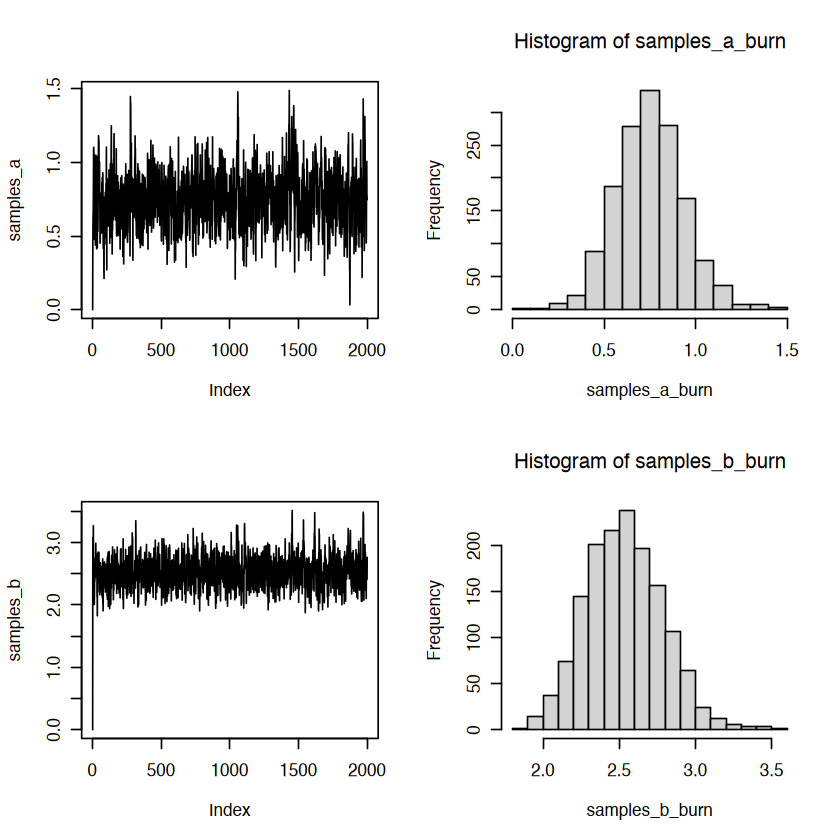

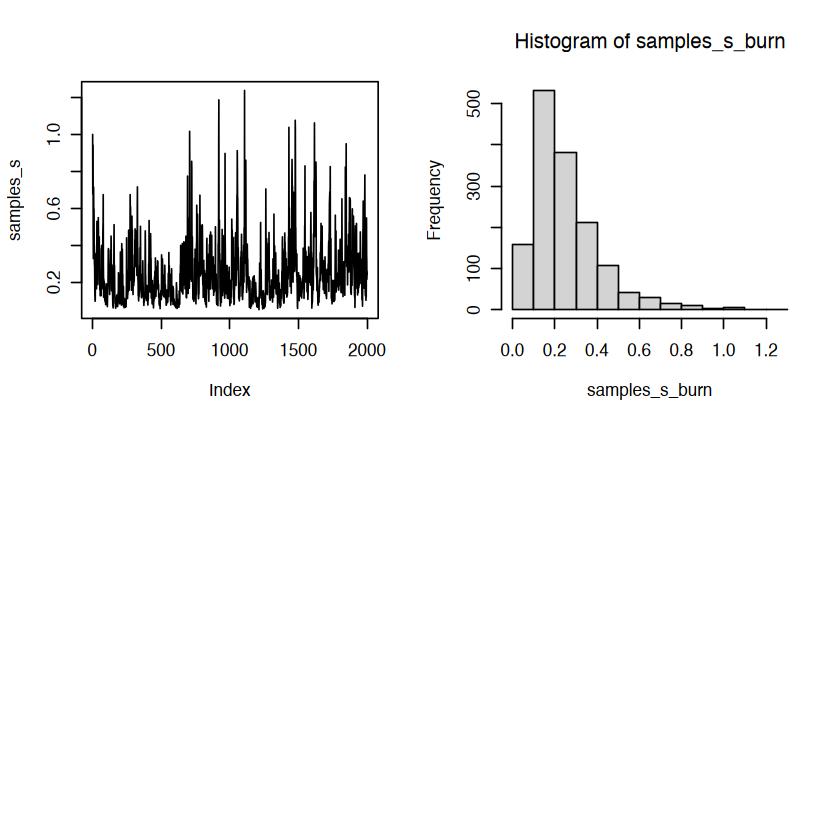

In [8]:
# FUNCTION: log-likelihood for alpha
lga <- function(alp, bet, eps, sda, z, n, m){
  th <- alp + bet*z + eps
  sum( m*th - n*log(1 + exp(th)) ) - (alp^2) / (2*sda^2) # (11.45)
}

# FUNCTION: log-likelihood for beta
lgb <- function(alp, bet, eps, sdb, z, n, m){
  th <- alp + bet*z + eps
  sum( m*th - n*log(1 + exp(th)) ) - (bet^2) / (2*sdb^2) # (11.46)
}

# FUNCTION : adaptive rejection sampling for alpha
# initial abscissae : { mu, xab(i), i=1,....,mu }
arsal <- function(mu, xab, pb, eps, sd, z, n, m) {
  jk <- 0
  u2 <- 1
  rat <- 0
  while(u2 > rat){
    jk <- jk + 1
    xx <- sort(xab) # {(x, pi(x)) for x in S}のx座標；{x for x in S}

    h <- 1:mu # {(x, pi(x)) for x in S}のy座標；{pi(x) for x in S}
    for (i in 1:mu){ h[i] <- lga(xx[i], pb, eps, sd, z, n, m) }

    st <- 1:(mu-1)
    for (i in 1:(mu-1)){ st[i] <- (h[i] - h[i+1]) / (xx[i] - xx[i+1]) }

    ss <- 1:(2*mu-2)
    ss[1] <- st[1]; ss[2] <- st[2]
    for (i in 2:(mu-2)){ ss[2*i-1] <- st[i-1]; ss[2*i] <- st[i+1] }
    ss[2*mu-3] <- st[mu-2]
    ss[2*mu-2] <- st[mu-1]

    xc <- 1:(2*mu-3) # PI_S(X)が折れ曲がる点のx座標（Sの区間のうち，最初と最後以外に凸点があるため，mu+(mu-1-2)=2mu-3）
    xc[1] <- xx[1]
    for (i in 2:(mu-2)){
      xc[2*i-2] <- xx[i]
      xc[2*i-1] <- (h[i+1] - h[i] + st[i-1]*xx[i] - st[i+1]*xx[i+1]) / (st[i-1] - st[i+1]) }
    xc[2*mu-4] <- xx[mu-1]
    xc[2*mu-3] <- xx[mu]

    cu <- 1:(2*mu-2)
    cu[1] <- h[1] - st[1]*xx[1]
    cu[2] <- h[2] - st[2]*xx[2]
    for (i in 2:(mu-2)) {
      cu[2*i-1] <- h[i] - st[i-1]*xx[i]
      cu[2*i]   <- h[i+1] - st[i+1]*xx[i+1]
    }
    cu[2*mu-3] <- h[mu-1] - st[mu-2]*xx[mu-1]
    cu[2*mu-2] <- h[mu] - st[mu-1]*xx[mu]

    yy <- 1:(2*mu-3) # PI_S(X)が折れ曲がる点のy座標
    yy[1] <- st[2]*xx[1] + cu[2]
    for (i in 2:(mu-2)) {
      yy[2*i-2] <- h[i]
      yy[2*i-1] <- ss[2*i-1]*xc[2*i-1] + cu[2*i-1]
    }
    yy[2*mu-4] <- h[mu-1]
    yy[2*mu-3] <- ss[2*mu-3]*xx[mu] + cu[2*mu-3]

    ff <- 1:(2*mu-2)
    s <- 0
    ff[1] <- exp(ss[1]*xc[1] + cu[1]) / ss[1]
    for (i in 2:(2*mu-3)) {
      ff[i] <- exp(cu[i])*(exp(ss[i]*xc[i]) - exp(ss[i]*xc[i - 1])) / ss[i]
      s <- s + ff[i]
    }
    ff[2*mu - 2] <- -exp(ss[2*mu-2]*xc[2*mu-3] + cu[2*mu - 2]) / ss[2*mu-2]

    s <- s + ff[1] + ff[2*mu-2]

    for (i in 1:(2*mu-2)) { ff[i] <- ff[i] / s }

    fg <- rep(0, 2*mu - 2)
    for (i in 1:(2*mu - 2)) {
      for (j in 1:i) {
        fg[i] <- fg[i] + ff[j]
      }
    }

    u <- runif(1, 0, 1)
    xprob <- 0
    i <- 0

    while(u > xprob) { i<-i+1; xprob<-fg[i] }

    k <- i
    ud <- ifelse(k>1, u-fg[k-1], u)
    aaa <- ifelse(k>1, exp(ss[k]*xc[k-1]), 0)
    xget <- log(aaa + s*ud*ss[k]/exp(cu[k])) / ss[k]

    u2 <- runif(1, 0, 1)
    t1 <- lga(xget, pb, eps, sd, z, n, m)
    t2 <- ss[k]*xget+cu[k]
    rat <- exp(t1-t2)

    xab <- c(xab, xget)
    mu <- mu + 1
  }
  return(xget)
}

# FUNCTION : adaptive rejection sampling for beta
# initial abscissae : { mu, xab(i), i=1,....,mu }
arsbe <- function(mu, yab, pa, eps, sd, z, n, m) {
  jk <- 0
  u2 <- 1
  rat <- 0
  while(u2 > rat){
    jk <- jk + 1
    xx <- sort(yab) # {(x, pi(x)) for x in S}のx座標；{x for x in S}

    h <- 1:mu # {(x, pi(x)) for x in S}のy座標；{pi(x) for x in S}
    for (i in 1:mu){ h[i] <- lgb(pa, xx[i], eps, sd, z, n, m) }

    st <- 1:(mu-1)
    for (i in 1:(mu-1)){ st[i] <- (h[i] - h[i+1]) / (xx[i] - xx[i+1]) }

    ss <- 1:(2*mu-2)
    ss[1] <- st[1]; ss[2] <- st[2]
    for (i in 2:(mu-2)){ ss[2*i-1] <- st[i-1]; ss[2*i] <- st[i+1] }
    ss[2*mu-3] <- st[mu-2]
    ss[2*mu-2] <- st[mu-1]

    xc <- 1:(2*mu-3) # PI_S(X)が折れ曲がる点のx座標（Sの区間のうち，最初と最後以外に凸点があるため，mu+(mu-1-2)=2mu-3）
    xc[1] <- xx[1]
    for (i in 2:(mu-2)){
      xc[2*i-2] <- xx[i]
      xc[2*i-1] <- (h[i+1] - h[i] + st[i-1]*xx[i] - st[i+1]*xx[i+1]) / (st[i-1] - st[i+1]) }
    xc[2*mu-4] <- xx[mu-1]
    xc[2*mu-3] <- xx[mu]

    cu <- 1:(2*mu-2)
    cu[1] <- h[1] - st[1]*xx[1]
    cu[2] <- h[2] - st[2]*xx[2]
    for (i in 2:(mu-2)) {
      cu[2*i-1] <- h[i] - st[i-1]*xx[i]
      cu[2*i]   <- h[i+1] - st[i+1]*xx[i+1]
    }
    cu[2*mu-3] <- h[mu-1] - st[mu-2]*xx[mu-1]
    cu[2*mu-2] <- h[mu] - st[mu-1]*xx[mu]

    yy <- 1:(2*mu-3) # PI_S(X)が折れ曲がる点のy座標
    yy[1] <- st[2]*xx[1] + cu[2]
    for (i in 2:(mu-2)) {
      yy[2*i-2] <- h[i]
      yy[2*i-1] <- ss[2*i-1]*xc[2*i-1] + cu[2*i-1]
    }
    yy[2*mu-4] <- h[mu-1]
    yy[2*mu-3] <- ss[2*mu-3]*xx[mu] + cu[2*mu-3]

    ff <- 1:(2*mu-2)
    s <- 0
    ff[1] <- exp(ss[1]*xc[1] + cu[1]) / ss[1]
    for (i in 2:(2*mu-3)) {
      ff[i] <- exp(cu[i])*(exp(ss[i]*xc[i]) - exp(ss[i]*xc[i - 1])) / ss[i]
      s <- s + ff[i]
    }
    ff[2*mu - 2] <- -exp(ss[2*mu-2]*xc[2*mu-3] + cu[2*mu - 2]) / ss[2*mu-2]

    s <- s + ff[1] + ff[2*mu-2]

    for (i in 1:(2*mu-2)) { ff[i] <- ff[i] / s }

    fg <- rep(0, 2*mu - 2)
    for (i in 1:(2*mu - 2)) {
      for (j in 1:i) {
        fg[i] <- fg[i] + ff[j]
      }
    }

    u <- runif(1, 0, 1)
    xprob <- 0
    i <- 0

    while(u > xprob) { i<-i+1; xprob<-fg[i] }

    k <- i
    ud <- ifelse(k>1, u-fg[k-1], u)
    aaa <- ifelse(k>1, exp(ss[k]*xc[k-1]), 0)
    xget <- log(aaa + s*ud*ss[k]/exp(cu[k])) / ss[k]

    u2 <- runif(1, 0, 1)
    t1 <- lgb(pa, xget, eps, sd, z, n, m)
    t2 <- ss[k]*xget+cu[k]
    rat <- exp(t1-t2)

    yab <- c(yab, xget)
    mu <- mu + 1
  }
  return(xget)
}

# FUNCTION: log-likelihood for epsilon[index]
lgei <- function(ei, index, alp, bet, epsni, tau, z, n, m){
  eps <- append(epsni, ei, after = index-1)
  th <- alp + bet*z + eps
  sum( m*th - n*log(1 + exp(th)) ) - (ei^2) * tau / 2 # (11.47)
}

# FUNCTION : adaptive rejection sampling for epsilon[index]
# initial abscissae : { mu, xab(i), i=1,....,mu }
arsei <- function(mu, zab, pa, pb, eps, index, tau, z, n, m) {
  epsni <- eps[-index]
  jk <- 0
  u2 <- 1
  rat <- 0
  while(u2 > rat & mu < 10){
    jk <- jk + 1
    xx <- sort(zab) # {(x, pi(x)) for x in S}のx座標；{x for x in S}

    h <- 1:mu # {(x, pi(x)) for x in S}のy座標；{pi(x) for x in S}
    for (i in 1:mu){ h[i] <- lgei(xx[i], index, pa, pb, epsni, tau, z, n, m) }

    st <- 1:(mu-1)
    for (i in 1:(mu-1)){ st[i] <- (h[i] - h[i+1]) / (xx[i] - xx[i+1]) }

    ss <- 1:(2*mu-2)
    ss[1] <- st[1]; ss[2] <- st[2]
    for (i in 2:(mu-2)){ ss[2*i-1] <- st[i-1]; ss[2*i] <- st[i+1] }
    ss[2*mu-3] <- st[mu-2]
    ss[2*mu-2] <- st[mu-1]

    xc <- 1:(2*mu-3) # PI_S(X)が折れ曲がる点のx座標（Sの区間のうち，最初と最後以外に凸点があるため，mu+(mu-1-2)=2mu-3）
    xc[1] <- xx[1]
    for (i in 2:(mu-2)){
      xc[2*i-2] <- xx[i]
      xc[2*i-1] <- (h[i+1] - h[i] + st[i-1]*xx[i] - st[i+1]*xx[i+1]) / (st[i-1] - st[i+1]) }
    xc[2*mu-4] <- xx[mu-1]
    xc[2*mu-3] <- xx[mu]

    cu <- 1:(2*mu-2)
    cu[1] <- h[1] - st[1]*xx[1]
    cu[2] <- h[2] - st[2]*xx[2]
    for (i in 2:(mu-2)) {
      cu[2*i-1] <- h[i] - st[i-1]*xx[i]
      cu[2*i]   <- h[i+1] - st[i+1]*xx[i+1]
    }
    cu[2*mu-3] <- h[mu-1] - st[mu-2]*xx[mu-1]
    cu[2*mu-2] <- h[mu] - st[mu-1]*xx[mu]

    yy <- 1:(2*mu-3) # PI_S(X)が折れ曲がる点のy座標
    yy[1] <- st[2]*xx[1] + cu[2]
    for (i in 2:(mu-2)) {
      yy[2*i-2] <- h[i]
      yy[2*i-1] <- ss[2*i-1]*xc[2*i-1] + cu[2*i-1]
    }
    yy[2*mu-4] <- h[mu-1]
    yy[2*mu-3] <- ss[2*mu-3]*xx[mu] + cu[2*mu-3]

    ff <- 1:(2*mu-2)
    s <- 0
    ff[1] <- exp(ss[1]*xc[1] + cu[1]) / ss[1]
    for (i in 2:(2*mu-3)) {
      ff[i] <- (exp(ss[i]*xc[i]+cu[i]) - exp(ss[i]*xc[i - 1]+cu[i])) / ss[i]
      s <- s + ff[i]
    }
    ff[2*mu - 2] <- -exp(ss[2*mu-2]*xc[2*mu-3] + cu[2*mu - 2]) / ss[2*mu-2]

    s <- s + ff[1] + ff[2*mu-2]

    for (i in 1:(2*mu-2)) { ff[i] <- ff[i] / s }

    fg <- rep(0, 2*mu - 2)
    for (i in 1:(2*mu - 2)) {
      for (j in 1:i) {
        fg[i] <- fg[i] + ff[j]
      }
    }

    u <- runif(1, 0, 1)
    xprob <- 0
    i <- 0

    while (u > xprob) { i <- i+1; xprob <- fg[i] }

    k <- i
    ud <- ifelse(k>1, u-fg[k-1], u)
    aaa <- ifelse(k>1, exp(ss[k]*xc[k-1]), 0)
    xget <- log(aaa + s*ud*ss[k]/exp(cu[k])) / ss[k]

    u2 <- runif(1, 0, 1)
    t1 <- lgei(xget, index, pa, pb, epsni, tau, z, n, m)
    t2 <- ss[k]*xget+cu[k]
    rat <- exp(t1-t2)

    zab <- c(zab, xget)
    mu <- mu + 1

    if (mu == 10) { xget <- eps[index] } # 非収束時の対応．．．
  }
  return(xget)
}

ex11_9 <- function(n_iter, burn_in, a0, sda, b0, sdb, e0, t0){
  K <- length(e0)

  samples_a <- rep(0, n_iter); samples_b <- rep(0, n_iter)
  samples_a[1] <- a0; samples_b[1] <- b0; alp <- a0; bet <- b0

  samples_e <- matrix(, n_iter, K)
  samples_e[1, ] <- e0; eps <- e0

  samples_t <- rep(0, n_iter)
  samples_t[1] <- t0; tau <- t0

  x <- c(1.681, 1.724, 1.755, 1.784, 1.811, 1.837, 1.861, 1.884)
  z <- (x-mean(x))/sqrt(var(x))
  n <- c(59, 60, 62, 56, 63, 59, 62, 60)
  m <- c(4, 10, 19, 31, 52, 53, 60, 60)

  xab <- c(-1, 0, 1, 2); mua <- length(xab)
  yab <- c(0, 1, 2, 3, 4); mub <- length(yab)
  zab <- c(-1, 0, 1, 2); mue <- length(zab)

  pb <- txtProgressBar(min = 2, max = n_iter, style = 3)

  for (i in 2:n_iter){
    alp <- arsal(mua, xab, bet, eps, sda, z, n, m)
    samples_a[i] <- alp

    bet <- arsbe(mub, yab, alp, eps, sdb, z, n, m)
    samples_b[i] <- bet

    for (index in 1:K) {
      ei <- arsei(mue, zab, alp, bet, eps, index, tau, z, n, m)
      epsni <- eps[-index]
      eps <- append(epsni, ei, after = index-1)
    }
    samples_e[i, ] <- eps

    a <- 0.01; b <- 0.01
    tau <- rgamma(1, a + K/2, b + sum(eps^2)/2) # (11.48)
    samples_t[i] <- tau

    Sys.sleep(0.05)
    setTxtProgressBar(pb, i)
  }

  samples_a_burn <- as.vector(na.omit(samples_a[burn_in+1:n_iter]))
  samples_b_burn <- as.vector(na.omit(samples_b[burn_in+1:n_iter]))
  samples_t_burn <- as.vector(na.omit(samples_t[burn_in+1:n_iter]))

  samples_s <- 1 / sqrt(samples_t)
  samples_s_burn <- 1 / sqrt(samples_t_burn)

  samples_a_burn_first <- samples_a_burn[1:floor(length(samples_a_burn)/2)]
  samples_a_burn_latter <- samples_a_burn[(floor(length(samples_a_burn)/2)+1):length(samples_a_burn)]

  samples_b_burn_first <- samples_b_burn[1:floor(length(samples_b_burn)/2)]
  samples_b_burn_latter <- samples_b_burn[(floor(length(samples_b_burn)/2)+1):length(samples_b_burn)]

  Za <- (mean(samples_a_burn_first) - mean(samples_a_burn_latter)) / sqrt(var(samples_a_burn_first) + var(samples_a_burn_latter)) * sqrt((n_iter - burn_in)/2)
  Zb <- (mean(samples_b_burn_first) - mean(samples_b_burn_latter)) / sqrt(var(samples_b_burn_first) + var(samples_b_burn_latter)) * sqrt((n_iter - burn_in)/2)

  par(mfrow=c(2, 2))
  par(bg = "white")
  plot(samples_a, type = "l")
  hist(samples_a_burn)

  plot(samples_b, type = "l")
  hist(samples_b_burn)

  plot(samples_s, type = "l")
  hist(samples_s_burn)

  alpha_est = mean(samples_a_burn)
  beta_est = mean(samples_b_burn)

  cat("\n")
  cat("alpha (std)", alpha_est, sqrt(var(samples_a_burn)), Za, "\n")
  cat("alpha", alpha_est - mean(x) * beta_est / sqrt(var(x)), "\n")
  cat("beta (std)", beta_est, sqrt(var(samples_b_burn)), Zb, "\n")
  cat("beta", beta_est / sqrt(var(x)), "\n")
  cat("sigma", mean(samples_s_burn), sqrt(var(samples_s_burn)))
}

ex11_9(2000, 500, 0, 5, 0, 5, rep(0, 8), 1)

#### 例題11.10
Stanを使用して階層的条件付き独立モデルを構築する

In [9]:
library(tidyverse)

df <- read.csv("./src/table_11_4.csv")

df_long <- df %>%
  pivot_longer(cols = c(d8:d36), names_to = "day", values_to = "weight") %>%
  mutate(day = as.integer(str_replace_all(day, "d", ""))) %>%
  mutate(z = day - mean(day))

head(df_long)

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


RatNo,day,weight,z
<int>,<int>,<int>,<dbl>
1,8,151,-14
1,15,199,-7
1,22,246,0
1,29,283,7
1,36,320,14
2,8,145,-14


In [10]:
library(cmdstanr)

stan_data <- list(
  N = nrow(df_long),
  J = length(unique(df_long$RatNo)),
  RatNo = df_long$RatNo,
  day = df_long$z,
  weight = df_long$weight,
  mean_day = mean(df_long$day)
)

model <- cmdstan_model("./ex11_10.stan")

fit <- model$sample(
  data = stan_data,
  iter_warmup = 500,
  iter_sampling = 1500,
  chains = 1
)


This is cmdstanr version 0.8.0

- CmdStanR documentation and vignettes: mc-stan.org/cmdstanr

- CmdStan path: /Users/mkawamura/.cmdstan/cmdstan-2.40.0

- CmdStan version: 2.40.0



Running MCMC with 1 chain...

Chain 1 Iteration:    1 / 2000 [  0%]  (Warmup) 
Chain 1 Iteration:  100 / 2000 [  5%]  (Warmup) 
Chain 1 Iteration:  200 / 2000 [ 10%]  (Warmup) 
Chain 1 Iteration:  300 / 2000 [ 15%]  (Warmup) 
Chain 1 Iteration:  400 / 2000 [ 20%]  (Warmup) 
Chain 1 Iteration:  500 / 2000 [ 25%]  (Warmup) 
Chain 1 Iteration:  501 / 2000 [ 25%]  (Sampling) 
Chain 1 Iteration:  600 / 2000 [ 30%]  (Sampling) 
Chain 1 Iteration:  700 / 2000 [ 35%]  (Sampling) 
Chain 1 Iteration:  800 / 2000 [ 40%]  (Sampling) 
Chain 1 Iteration:  900 / 2000 [ 45%]  (Sampling) 
Chain 1 Iteration: 1000 / 2000 [ 50%]  (Sampling) 
Chain 1 Iteration: 1100 / 2000 [ 55%]  (Sampling) 
Chain 1 Iteration: 1200 / 2000 [ 60%]  (Sampling) 
Chain 1 Iteration: 1300 / 2000 [ 65%]  (Sampling) 
Chain 1 Iteration: 1400 / 2000 [ 70%]  (Sampling) 
Chain 1 Iteration: 1500 / 2000 [ 75%]  (Sampling) 
Chain 1 Iteration: 1600 / 2000 [ 80%]  (Sampling) 
Chain 1 Iteration: 1700 / 2000 [ 85%]  (Sampling) 
Chain 1 Itera

In [11]:
fit$summary(c("mu_a", "mu_b", "born_weight", "sigma_e"))

variable,mean,median,sd,mad,q5,q95,rhat,ess_bulk,ess_tail
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
mu_a,242.238234,242.158675,2.7767903,2.7735369,237.731911,246.919294,1.0100068,134.8861,249.2927
mu_b,6.182949,6.183401,0.1086878,0.1042977,6.006387,6.363019,1.0223407,263.7402,509.9206
born_weight,106.213360,106.258495,3.6961698,3.7357220,100.217040,112.107618,0.9998128,176.6904,375.2480
sigma_e,6.081394,6.044775,0.4544268,0.4499059,5.407348,6.890467,1.0061993,653.8073,849.5456


This is bayesplot version 1.16.0

- Online documentation and vignettes at mc-stan.org/bayesplot

- bayesplot theme set to bayesplot::theme_default()

   * Does _not_ affect other ggplot2 plots

   * See ?bayesplot_theme_set for details on theme setting



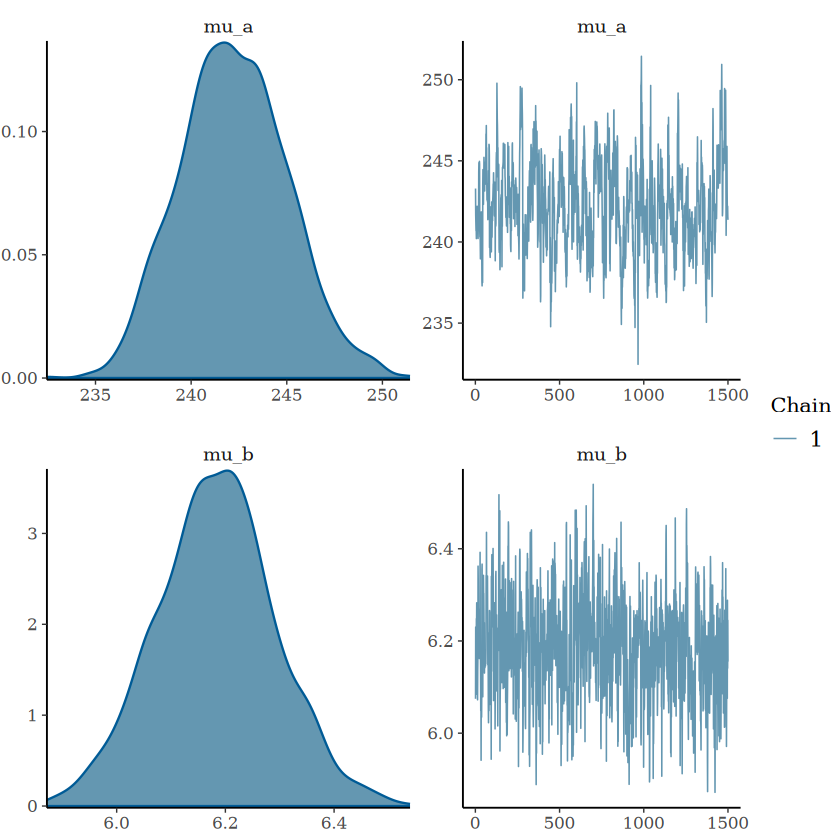

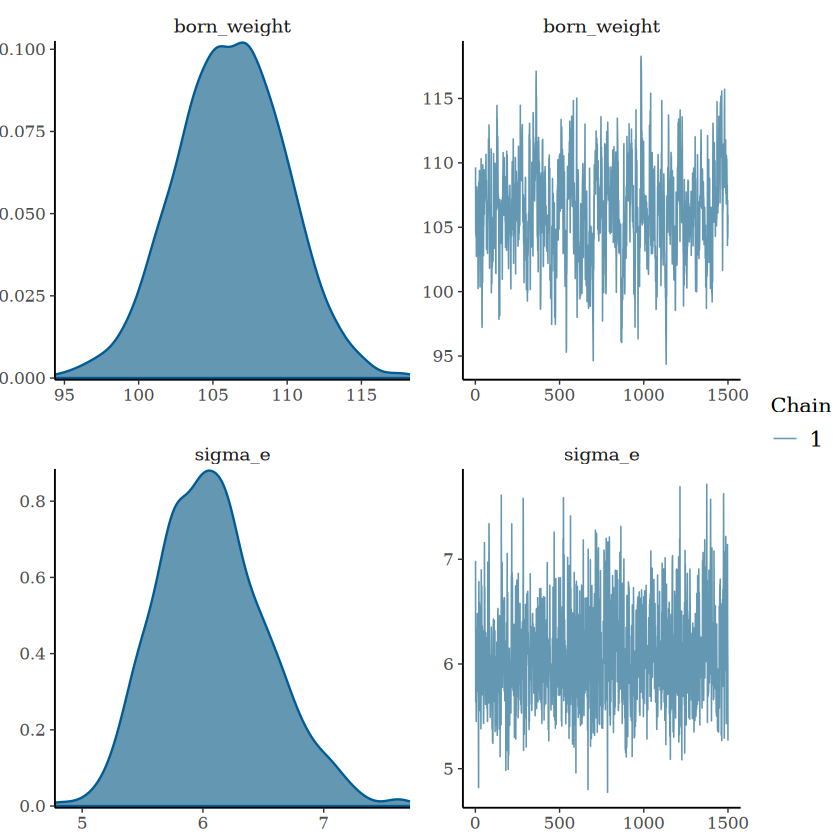

In [12]:
library(bayesplot)

fit$draws(c("mu_a", "mu_b")) %>% mcmc_combo
fit$draws(c("born_weight", "sigma_e")) %>% mcmc_combo